# **Motivação: o problema do *picking* de velocidade**

Este *notebook* contextualiza o Exercício 7 com exemplos gráficos. A ideia é partir da aquisição sísmica e chegar até o espectro de velocidade usado no laboratório, mostrando o que é o *picking* e por que vale a pena automatizá-lo.

**Roteiro**

1. Aquisição CMP
2. A hipérbole de *normal moveout* (NMO)
3. Correção NMO e o papel da velocidade
4. Análise de velocidade por *semblance*
5. O espectro real do laboratório (`vel_spec.bin775`)
6. Por que automatizar o *picking*?
7. *Picking* como clusterização (K-means)

Os itens 1 a 4 usam uma família CMP sintética gerada aqui mesmo; os itens 5 e 7 usam o dado real do laboratório.

In [8]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})

## 1. Aquisição CMP

Na sísmica de reflexão, um mesmo ponto em subsuperfície é iluminado por vários pares fonte–receptor com afastamentos (*offsets*) diferentes, todos simétricos em torno do mesmo ponto médio. O conjunto desses traços forma uma família CMP (*common midpoint*).

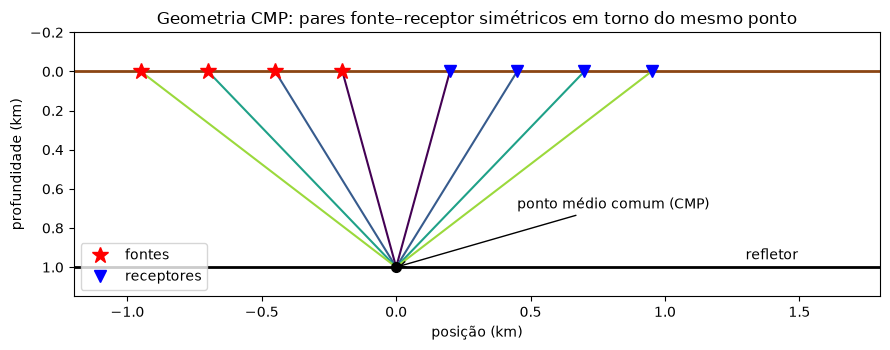

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.6))
z_ref, xm = 1.0, 0.0
offsets = [0.4, 0.9, 1.4, 1.9]
cores = plt.cm.viridis(np.linspace(0, 0.85, len(offsets)))
ax.axhline(0, color='saddlebrown', lw=2)
ax.axhline(z_ref, color='k', lw=2)
ax.text(1.3, z_ref - 0.04, 'refletor')
for h, c in zip(offsets, cores):
    s, r = xm - h/2, xm + h/2
    ax.plot([s, xm, r], [0, z_ref, 0], color=c, lw=1.5)
    ax.plot(s, 0, marker='*', color='red', ms=12)
    ax.plot(r, 0, marker='v', color='blue', ms=9)
ax.plot(xm, z_ref, 'ko', ms=7)
ax.annotate('ponto médio comum (CMP)', (xm, z_ref), (0.45, 0.7), arrowprops=dict(arrowstyle='->'))
ax.plot([], [], '*', color='red', ms=12, ls='', label='fontes')
ax.plot([], [], 'v', color='blue', ms=9, ls='', label='receptores')
ax.set_xlim(-1.2, 1.8); ax.set_ylim(1.15, -0.2)
ax.set_xlabel('posição (km)'); ax.set_ylabel('profundidade (km)')
ax.set_title('Geometria CMP: pares fonte–receptor simétricos em torno do mesmo ponto')
ax.legend(loc='lower left')
plt.tight_layout(); plt.show()

## 2. A hipérbole de NMO

Quanto maior o *offset*, maior o caminho percorrido pela onda e mais tarde ela chega. Para um refletor horizontal, o tempo de chegada em função do *offset* $x$ segue, aproximadamente, a hipérbole de *normal moveout* (NMO):

$$t(x) = \sqrt{t_0^2 + \frac{x^2}{v_{\text{NMO}}^2}}$$

onde $v_{\text{NMO}}$ é a velocidade de empilhamento e $t_0$ é o tempo de trânsito duplo (ida e volta) com afastamento nulo, isto é, o tempo que a onda levaria para descer verticalmente do CMP até o refletor e voltar se fonte e receptor estivessem no mesmo ponto ($x = 0$, incidência normal). Para um meio de velocidade $v$ e refletor à profundidade $z$,

$$t_0 = \frac{2z}{v},$$

e fazendo $x = 0$ na hipérbole obtém-se $t(0) = t_0$: $t_0$ é o ápice da hipérbole. Como não depende do *offset*, $t_0$ funciona como "endereço" de cada refletor no tempo e é o eixo vertical tanto da seção corrigida de NMO quanto do espectro de velocidade.

Abaixo, uma família CMP sintética com quatro refletores (pulso Ricker de 25 Hz e ruído aleatório). A velocidade aumenta com a profundidade, então as hipérboles mais profundas são mais "abertas".

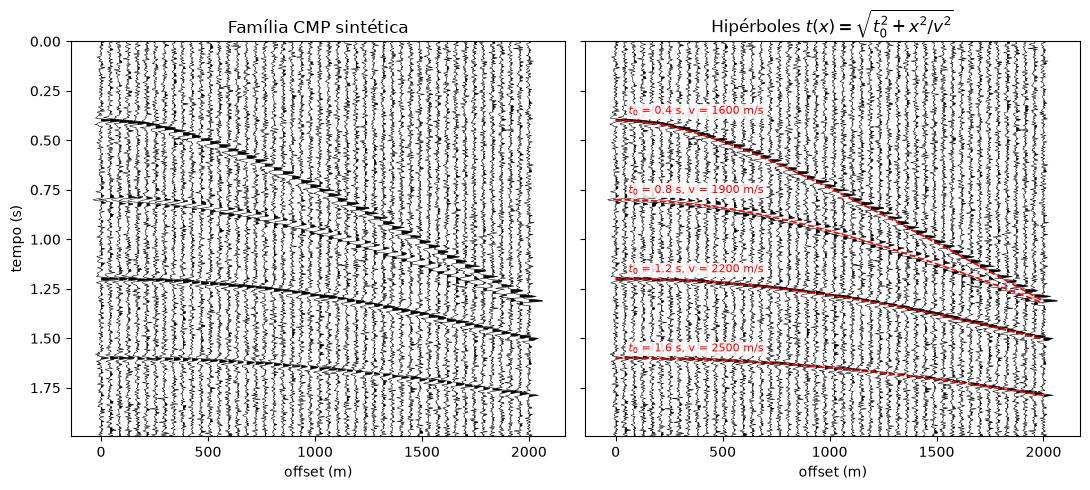

In [10]:
dt, tmax = 0.004, 2.0
t = np.arange(0, tmax, dt)
x = np.linspace(0, 2000, 48)                      # offsets (m)
t0_ref  = np.array([0.40, 0.80, 1.20, 1.60])      # tempos de afastamento nulo (s)
v_ref   = np.array([1600, 1900, 2200, 2500])      # velocidades NMO (m/s)
amp_ref = np.array([1.0, -0.8, 0.9, 0.7])

def ricker(f, dt, n=61):
    tw = (np.arange(n) - n//2) * dt
    a = (np.pi * f * tw)**2
    return (1 - 2*a) * np.exp(-a)

w = ricker(25, dt)
rng = np.random.default_rng(0)
gather = np.zeros((len(t), len(x)))
for t0, v, a in zip(t0_ref, v_ref, amp_ref):
    tx = np.sqrt(t0**2 + (x/v)**2)                # hipérbole NMO
    idx = np.round(tx/dt).astype(int)
    ok = idx < len(t)
    gather[idx[ok], np.where(ok)[0]] += a
gather = np.apply_along_axis(lambda tr: np.convolve(tr, w, 'same'), 0, gather)
gather += 0.15 * rng.standard_normal(gather.shape)

def wiggle(ax, d, x, t, titulo=''):
    passo = x[1] - x[0]
    d = d / np.abs(d).max() * passo * 1.8
    for i, xi in enumerate(x):
        tr = d[:, i]
        ax.plot(xi + tr, t, 'k', lw=0.4)
        ax.fill_betweenx(t, xi, xi + tr, where=tr > 0, color='k', lw=0)
    ax.set_ylim(t[-1], t[0]); ax.set_xlabel('offset (m)'); ax.set_title(titulo)

fig, axs = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
wiggle(axs[0], gather, x, t, titulo='Família CMP sintética')
axs[0].set_ylabel('tempo (s)')
wiggle(axs[1], gather, x, t, titulo='Hipérboles $t(x)=\\sqrt{t_0^2+x^2/v^2}$')
for t0, v in zip(t0_ref, v_ref):
    axs[1].plot(x, np.sqrt(t0**2 + (x/v)**2), 'r--', lw=1.2)
    axs[1].text(60, t0 - 0.03, f'$t_0$ = {t0} s, v = {v} m/s', color='r', fontsize=8,
                 bbox=dict(fc='white', ec='none', alpha=0.85, pad=1))
plt.tight_layout(); plt.show()

## 3. Correção NMO e o papel da velocidade

Para empilhar os traços (somá-los e aumentar a razão sinal/ruído) é preciso primeiro remover o *moveout*, isto é, deslocar cada amostra de $t(x)$ para $t_0$. Isso só funciona se a função $v_{\text{NMO}}(t_0)$ for conhecida:

- com a velocidade correta, os eventos ficam horizontais e somam de forma construtiva;
- com velocidade baixa, a correção é excessiva e os eventos se curvam para cima;
- com velocidade alta, a correção é insuficiente e os eventos continuam curvados para baixo.

(A região em branco no canto superior direito é o *stretch mute*: amostras muito esticadas pela correção são zeradas.)

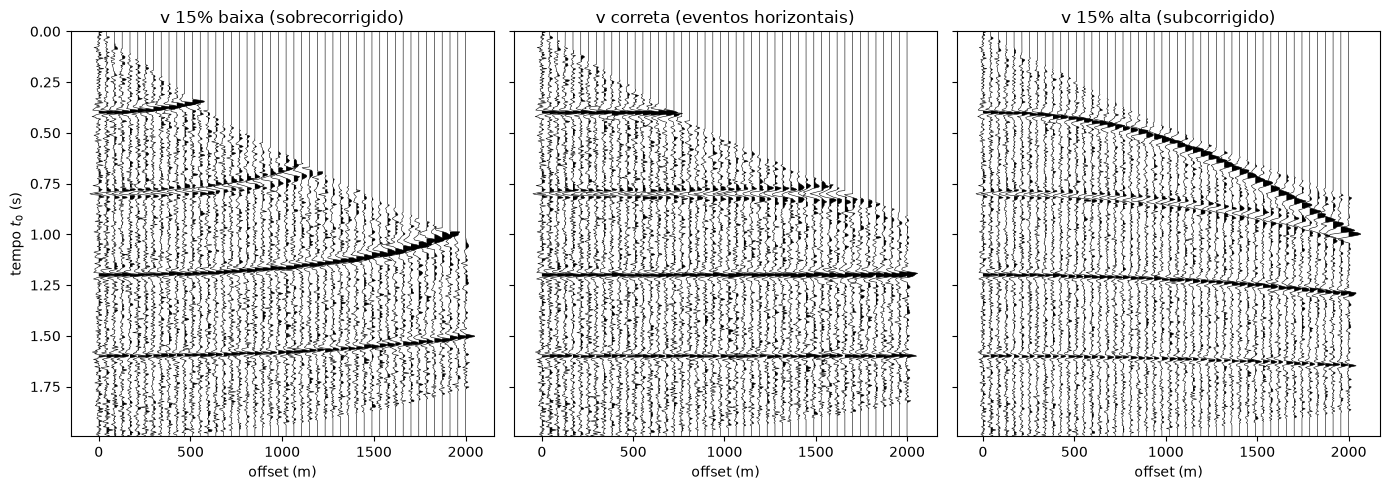

In [11]:
def nmo(d, x, t, v_t0, mute=0.5):
    """Correção NMO: para cada t0 lê a amostra em t(x) = sqrt(t0^2 + x^2/v(t0)^2).
    Amostras com estiramento (t(x) - t0)/t0 > mute são zeradas (stretch mute)."""
    out = np.zeros_like(d)
    for i, xi in enumerate(x):
        tx = np.sqrt(t**2 + (xi / v_t0)**2)
        out[:, i] = np.interp(tx, t, d[:, i], right=0)
        out[(tx - t) > mute * np.maximum(t, dt), i] = 0
    return out

v_true = np.interp(t, t0_ref, v_ref)              # função de velocidade correta v(t0)
casos = [(0.85, 'v 15% baixa (sobrecorrigido)'), (1.0, 'v correta (eventos horizontais)'),
         (1.15, 'v 15% alta (subcorrigido)')]
fig, axs = plt.subplots(1, 3, figsize=(14, 5), sharey=True)
for ax, (f, tit) in zip(axs, casos):
    wiggle(ax, nmo(gather, x, t, f * v_true), x, t, titulo=tit)
axs[0].set_ylabel('tempo $t_0$ (s)')
plt.tight_layout(); plt.show()

## 4. Análise de velocidade por *semblance*

Na prática, $v_{\text{NMO}}(t_0)$ não é conhecida. A análise de velocidade testa um intervalo de velocidades e, para cada par $(t_0, v)$, mede a coerência dos traços ao longo da hipérbole correspondente com a *semblance*:

$$S(t_0, v) = \frac{\sum_{t \in W} \left( \sum_{i=1}^{N} a_i(t) \right)^2}{N \sum_{t \in W} \sum_{i=1}^{N} a_i(t)^2}$$

onde $a_i(t)$ são os $N$ traços corrigidos de NMO com a velocidade $v$ e $W$ é uma janela de tempo em torno de $t_0$. $S$ vale 1 quando todos os traços são idênticos (evento perfeitamente horizontalizado) e é próxima de 0 para ruído.

O resultado é o espectro de velocidade: uma imagem com $t_0$ na vertical e $v$ na horizontal, em que os máximos de energia indicam as velocidades que melhor horizontalizam cada evento. O *picking* consiste em escolher, nesse espectro, a sequência de pontos $(t_0, v)$ que acompanha esses máximos (círculos brancos), definindo a função de velocidade daquele CMP. Essa função é a base para a correção NMO, para o empilhamento e para os modelos de velocidade iniciais usados em migração e inversão.

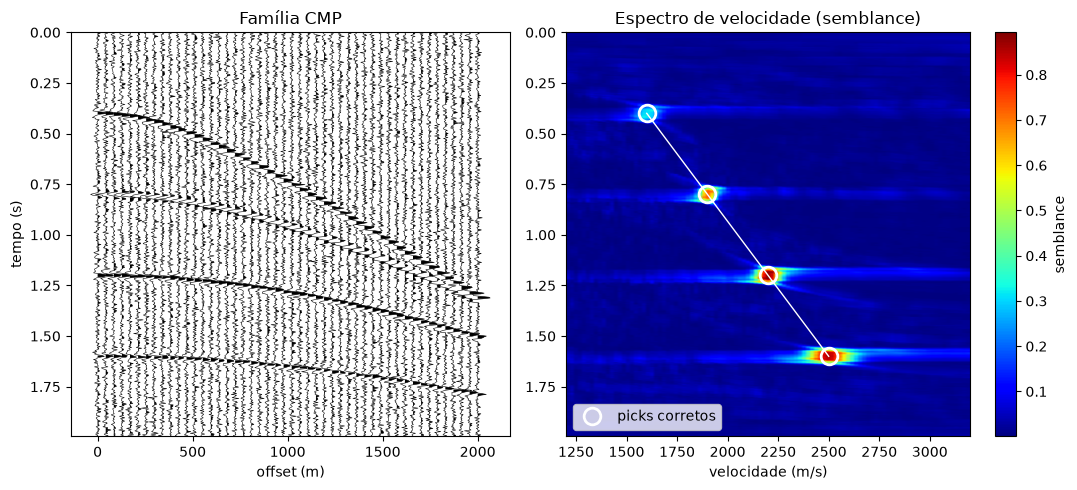

In [12]:
def semblance(d, x, t, vels, janela=11):
    S = np.zeros((len(t), len(vels)))
    k = np.ones(janela)
    for j, v in enumerate(vels):
        c = nmo(d, x, t, np.full_like(t, v))
        num = np.convolve(c.sum(1)**2, k, 'same')
        den = len(x) * np.convolve((c**2).sum(1), k, 'same')
        S[:, j] = num / (den + 1e-12)
    return S

vels = np.arange(1200, 3210, 20)
S = semblance(gather, x, t, vels)

fig, axs = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={'width_ratios': [1, 1.15]})
wiggle(axs[0], gather, x, t, titulo='Família CMP'); axs[0].set_ylabel('tempo (s)')
im = axs[1].imshow(S, aspect='auto', cmap='jet', extent=[vels[0], vels[-1], t[-1], t[0]])
axs[1].plot(v_ref, t0_ref, 'wo', mfc='none', ms=12, mew=2, label='picks corretos')
axs[1].plot(v_ref, t0_ref, 'w-', lw=1)
axs[1].set_xlabel('velocidade (m/s)'); axs[1].set_title('Espectro de velocidade (semblance)')
axs[1].legend(loc='lower left'); plt.colorbar(im, ax=axs[1], label='semblance')
plt.tight_layout(); plt.show()

## 5. O espectro real do laboratório

O arquivo `vel_spec.bin775` contém um espectro de velocidade real: uma matriz de $3521$ amostras de tempo (1 ms) $\times$ $381$ velocidades (de 1400 a 5200 m/s, a cada 10 m/s). Ele é lido e filtrado (mediana $3 \times 3$) da mesma forma que em `K_mean_cluster.m`.

Diferente do exemplo sintético, aqui não há picos isolados, e sim uma faixa contínua de energia, com muitas linhas horizontais de ruído e energia espalhada em tempos maiores. A estratégia mais simples de *picking*, tomar o máximo de cada amostra de tempo, mostra o problema: a curva resultante é ruidosa, salta lateralmente nas regiões de baixa energia e no topo (onde o espectro é praticamente nulo), e não é uma função de velocidade utilizável sem edição manual.

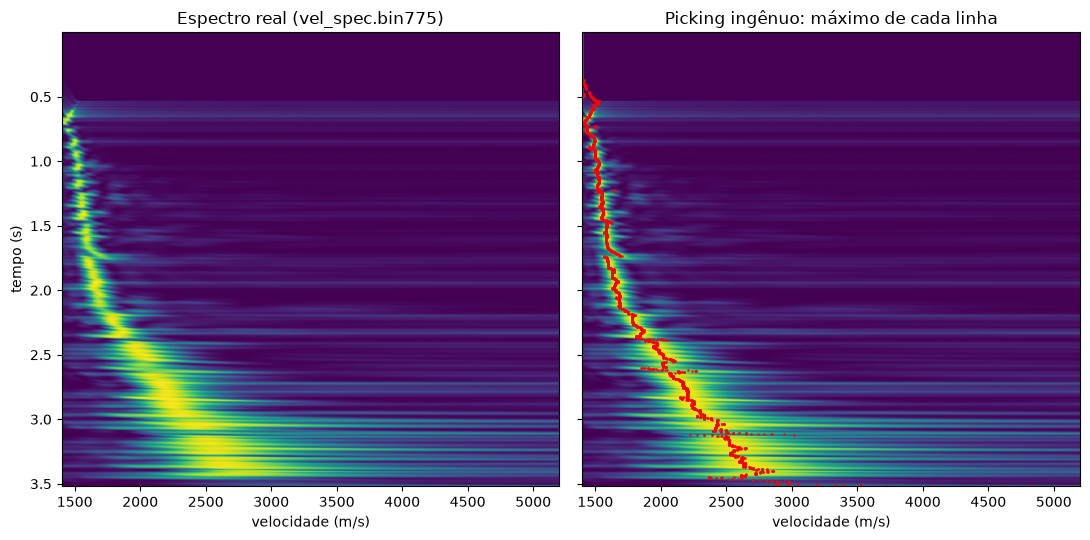

In [13]:
nt, n_vel = 3521, 381
vel_spec = np.fromfile('../vel_spec.bin775', dtype='<f4').reshape(n_vel, nt).T   # fread(fp,[nt,n_vel]) é column-major
pad = np.pad(vel_spec, 1, mode='edge')                                         # equivalente a medfilt2(vel_spec,[3,3])
vel_spec = np.median(np.lib.stride_tricks.sliding_window_view(pad, (3, 3)), axis=(-2, -1))
vv = 1400 + 10 * np.arange(n_vel)                                              # eixo de velocidades (m/s)
tt = 0.001 * np.arange(1, nt + 1)                                              # eixo de tempo (s)
ext = [vv[0], vv[-1], tt[-1], tt[0]]

pick_ingenuo = vv[np.argmax(vel_spec, axis=1)]                                  # máximo de cada amostra de tempo
fig, axs = plt.subplots(1, 2, figsize=(11, 5.5), sharey=True)
axs[0].imshow(vel_spec, aspect='auto', extent=ext)
axs[0].set_title('Espectro real (vel_spec.bin775)'); axs[0].set_ylabel('tempo (s)')
axs[1].imshow(vel_spec, aspect='auto', extent=ext)
axs[1].plot(pick_ingenuo, tt, 'r.', ms=1.5)
axs[1].set_title('Picking ingênuo: máximo de cada linha')
for ax in axs: ax.set_xlabel('velocidade (m/s)')
plt.tight_layout(); plt.show()

## 6. Por que automatizar o *picking*?

Tradicionalmente, um intérprete clica nos máximos do espectro, CMP por CMP. Esse procedimento tem limitações:

- Um levantamento 2D/3D moderno tem milhares a milhões de CMPs; mesmo analisando apenas um a cada $N$ CMPs, o *picking* manual consome semanas de trabalho de um intérprete.
- Intérpretes diferentes (ou o mesmo intérprete em dias diferentes) produzem *picks* diferentes; um método automático é determinístico e reprodutível.
- *Picks* automáticos aplicados de forma densa geram campos de velocidade mais suaves e consistentes entre CMPs vizinhos.
- Como visto no item 5, o espectro contém ruído e energia de múltiplas; um simples "máximo por linha" não basta, e é preciso um critério objetivo que olhe para a estrutura da faixa de energia como um todo.

## 7. *Picking* como clusterização (K-means)

No laboratório, o *picking* é tratado como um problema de clusterização não supervisionada, em três passos (reproduzidos abaixo em Python, seguindo `K_mean_cluster.m`):

1. Limiar: só os pontos com *semblance* acima de `prctile(prctile(vel_spec,90),90)` são mantidos. Eles formam uma nuvem de pontos cuja densidade acompanha a faixa de energia.
2. K-means: os pontos são agrupados usando como *features* apenas as coordenadas (índice de velocidade, índice de tempo), com $K = 15$ centróides inicializados ao longo da diagonal da grade.
3. Picks: cada centróide final é interpretado como um *pick*; ligando os centróides ordenados no tempo obtém-se a curva $v(t_0)$.

Como cada centróide é a média de muitos pontos, o resultado é bem mais suave e robusto que o *picking* por máximo de linha do item 5.

limiar = 63.5: 39440 de 1341501 pontos (2.9%)
clusters não vazios: 13 de 15


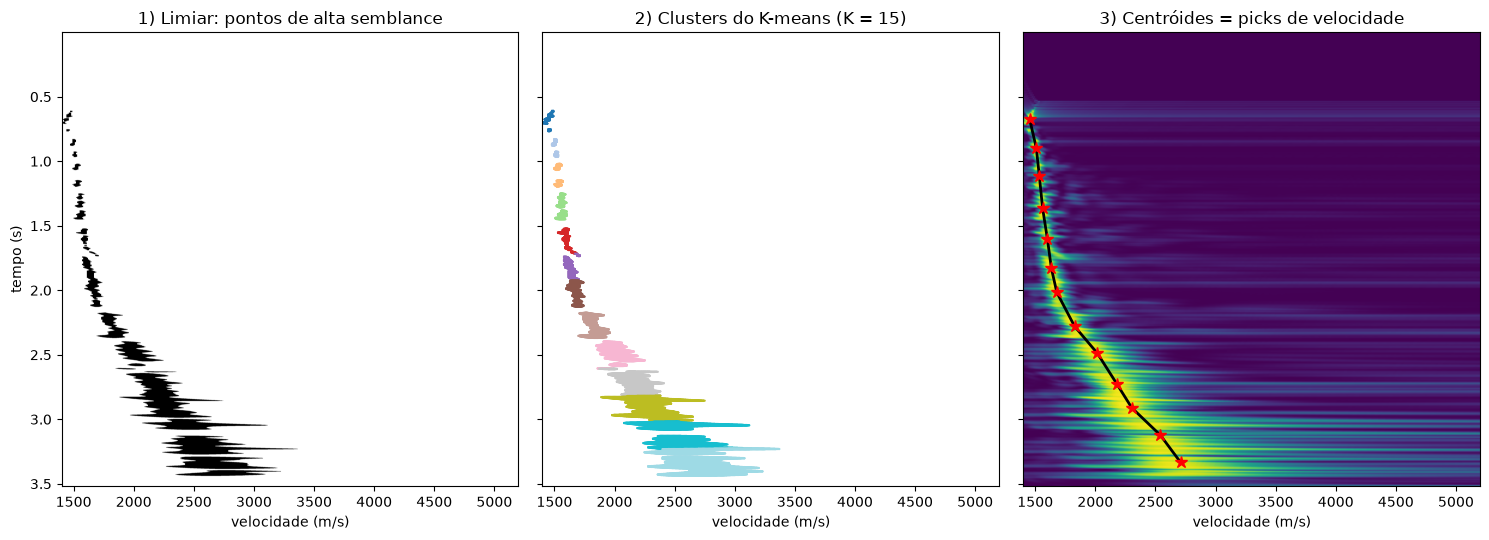

In [14]:
thres = np.percentile(np.percentile(vel_spec, 90, axis=0), 90)   # prctile(prctile(vel_spec,90),90)
iz, ix = np.nonzero(vel_spec > thres)
pts = np.column_stack([ix + 1, iz + 1]).astype(float)              # [índice de velocidade, índice de tempo]
print(f'limiar = {thres:.3g}: {len(pts)} de {vel_spec.size} pontos ({100*len(pts)/vel_spec.size:.1f}%)')

def kmeans_diag(pts, K, maxiter=15):
    """Mesmo K-means do K_mean_cluster.m (centróides iniciais na diagonal da grade).
    Como no script MATLAB, um cluster vazio tem o centróide levado para (0, 0)."""
    c = np.column_stack([np.floor(n_vel/(K+1)) * np.arange(1, K+1),
                         np.floor(nt/(K+1))    * np.arange(1, K+1)])
    for _ in range(maxiter):
        lab = ((pts[:, None, :] - c[None])**2).sum(-1).argmin(1)
        for k in range(K):
            c[k] = pts[lab == k].mean(0) if np.any(lab == k) else 0.0
    lab = ((pts[:, None, :] - c[None])**2).sum(-1).argmin(1)
    return c, lab

c, lab = kmeans_diag(pts, 15)
ativos = np.bincount(lab, minlength=len(c)) > 0                    # descarta clusters vazios
print(f'clusters não vazios: {ativos.sum()} de {len(c)}')
c = c[ativos]
fig, axs = plt.subplots(1, 3, figsize=(15, 5.5), sharey=True)
axs[0].imshow(vel_spec > thres, aspect='auto', extent=ext, cmap='gray_r')
axs[0].set_title('1) Limiar: pontos de alta semblance'); axs[0].set_ylabel('tempo (s)')
axs[1].scatter(1400 + 10*pts[:, 0], 0.001*pts[:, 1], c=lab, cmap='tab20', s=0.3)
axs[1].set_xlim(vv[0], vv[-1]); axs[1].set_title('2) Clusters do K-means (K = 15)')
axs[2].imshow(vel_spec, aspect='auto', extent=ext)
axs[2].plot(1400 + 10*c[:, 0], 0.001*c[:, 1], 'k-', lw=2)
axs[2].plot(1400 + 10*c[:, 0], 0.001*c[:, 1], 'r*', ms=9)
axs[2].set_title('3) Centróides = picks de velocidade')
for ax in axs: ax.set_xlabel('velocidade (m/s)')
plt.tight_layout(); plt.show()

Comparando com o item 5, os centróides do K-means fornecem uma função de velocidade suave, sem os saltos causados pelo ruído, e obtida sem intervenção manual. Dois detalhes desse procedimento são justamente o tema das questões do exercício:

Na Questão 1, questiona-se "qual o papel do limiar?" Como as *features* são só as coordenadas, sem ele o K-means não "vê" a *semblance*.

Na Questão 2, questiona-se "como escolher $K$?" Note que 2 dos 15 *clusters* ficaram vazios (no *script* MATLAB o centróide deles vai para a origem), um indício de que $K = 15$ é maior que o necessário.